# Avaliação de teste A/B em uma loja online

## 1. Contexto e objetivos

Uma loja online internacional realizou o teste `recommender_system_test` para avaliar mudanças relacionadas à introdução de um sistema de recomendação melhorado. O grupo A representa o controle, e o grupo B recebe a alteração.

O objetivo é verificar se o experimento foi realizado conforme o planejamento e comparar as conversões entre os grupos.

### Planejamento do teste

| Item | Especificação |
|---|---|
| Início | 07/12/2020 |
| Fim da entrada de novos usuários | 21/12/2020 |
| Término previsto | 01/01/2021 |
| Público | 15% dos novos usuários da União Europeia (UE) |
| Participantes esperados | 6.000 |
| Meta | Aumento de pelo menos 10% na conversão em cada etapa indicada, em até 14 dias após o cadastro |

### Objetivos da análise

- Examinar os tipos, valores ausentes e duplicatas.
- Avaliar público, atribuição aos grupos, sobreposição de participantes e cobertura temporal.
- Analisar conversões, eventos por usuário e eventos por dia.
- Aplicar testes z para comparar proporções de conversão.
- Apresentar conclusões sobre a execução e os resultados, considerando suas limitações.

### Ambiguidades do enunciado

A versão portuguesa apresenta `product_page → product_cart → purchase`, enquanto a inglesa informa `product_page → product_card → purchase`. Os eventos reais serão conferidos nos dados.

O grupo B é descrito como um “novo funil de pagamentos”, embora o propósito declarado seja avaliar um sistema de recomendação. Não há informações suficientes para esclarecer essa diferença.

A interpretação da meta de 10% e a contagem da janela de 14 dias serão definidas antes do cálculo das conversões.

## 2. Carregamento e diagnóstico dos dados

Serão examinadas a estrutura, a qualidade e a cobertura temporal dos quatro arquivos. As bases originais serão preservadas, e os tratamentos serão realizados em cópias de trabalho.

### 2.1. Preparação e apresentação

As bibliotecas, a paleta de cores e a função de formatação das tabelas são definidas a seguir.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

CORES = {
    "destaque": "#722F37",
    "comparacao": "#FFB7C5",
    "texto": "#2D3748",
    "apoio": "#718096",
    "fundo": "#F8F9FA",
    "grade": "#E2E8F0"
}

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.facecolor": CORES["fundo"],
    "axes.facecolor": CORES["fundo"],
    "text.color": CORES["texto"],
    "axes.labelcolor": CORES["texto"],
    "xtick.color": CORES["texto"],
    "ytick.color": CORES["texto"],
    "axes.titlesize": 16,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,
    "grid.color": CORES["grade"],
    "axes.spines.top": False,
    "axes.spines.right": False
})


def formatar_tabela(tabela, formatos=None):
    """Padroniza a aparência da tabela sem alterar os dados."""
    return (
        tabela.style
        .format(formatos, na_rep="—")
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", CORES["destaque"] + " !important"),
                    ("color", "white !important"),
                    ("text-align", "left"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("background-color", CORES["fundo"] + " !important"),
                    ("color", CORES["texto"] + " !important"),
                    ("text-align", "right"),
                    ("padding", "10px"),
                    ("border-bottom", f"1px solid {CORES['grade']}")
                ]
            }
        ])
    )

### 2.2. Estrutura das bases

| Base | Conteúdo | Finalidade |
|---|---|---|
| Marketing | Campanhas, regiões e datas | Verificar campanhas coincidentes com o experimento |
| Novos usuários | Usuário, cadastro, região e dispositivo | Conferir o público e as datas de entrada |
| Eventos | Usuário, data e hora, evento e detalhes | Analisar atividade e conversões |
| Participantes | Usuário, teste e grupo | Verificar a composição e a sobreposição dos grupos |

Os quatro arquivos CSV serão lidos da mesma pasta deste notebook. O sufixo `_raw` identifica as bases originais.

A inspeção apresenta dimensões, exemplos de registros, tipos e preenchimento das colunas.

In [2]:
marketing_raw = pd.read_csv(
    "ab_project_marketing_events_us.csv"
)
novos_usuarios_raw = pd.read_csv(
    "final_ab_new_users_upd_us.csv"
)
eventos_raw = pd.read_csv(
    "final_ab_events_upd_us.csv"
)
participantes_raw = pd.read_csv(
    "final_ab_participants_upd_us.csv"
)

bases_raw = {
    "Marketing": marketing_raw,
    "Novos usuários": novos_usuarios_raw,
    "Eventos": eventos_raw,
    "Participantes": participantes_raw
}

dimensoes_bases = pd.DataFrame(
    [base.shape for base in bases_raw.values()],
    index=bases_raw.keys(),
    columns=["Linhas", "Colunas"]
)

display(
    formatar_tabela(
        dimensoes_bases,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

,Linhas,Colunas
Marketing,14,4
Novos usuários,58.703,4
Eventos,423.761,4
Participantes,14.525,3


In [3]:
for nome, base in bases_raw.items():
    print(f"{nome.upper()} — primeiros cinco registros")
    display(formatar_tabela(base.head()))

    print(f"{nome.upper()} — tipos e preenchimento")
    base.info()
    print()

MARKETING — primeiros cinco registros


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19
3,Easter Promo,"EU, CIS, APAC, N.America",2020-04-12,2020-04-19
4,4th of July Promo,N.America,2020-07-04,2020-07-11


MARKETING — tipos e preenchimento
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   name       14 non-null     str  
 1   regions    14 non-null     str  
 2   start_dt   14 non-null     str  
 3   finish_dt  14 non-null     str  
dtypes: str(4)
memory usage: 1.3 KB

NOVOS USUÁRIOS — primeiros cinco registros


,user_id,first_date,region,device
0,D72A72121175D8BE,2020-12-07,EU,PC
1,F1C668619DFE6E65,2020-12-07,N.America,Android
2,2E1BF1D4C37EA01F,2020-12-07,EU,PC
3,50734A22C0C63768,2020-12-07,EU,iPhone
4,E1BDDCE0DAFA2679,2020-12-07,N.America,iPhone


NOVOS USUÁRIOS — tipos e preenchimento
<class 'pandas.DataFrame'>
RangeIndex: 58703 entries, 0 to 58702
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     58703 non-null  str  
 1   first_date  58703 non-null  str  
 2   region      58703 non-null  str  
 3   device      58703 non-null  str  
dtypes: str(4)
memory usage: 3.7 MB

EVENTOS — primeiros cinco registros


,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.990000
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.990000
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.990000
3,96F27A054B191457,2020-12-07 04:02:40,purchase,4.990000
4,1FD7660FDF94CA1F,2020-12-07 10:15:09,purchase,4.990000


EVENTOS — tipos e preenchimento
<class 'pandas.DataFrame'>
RangeIndex: 423761 entries, 0 to 423760
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     423761 non-null  str    
 1   event_dt    423761 non-null  str    
 2   event_name  423761 non-null  str    
 3   details     60314 non-null   float64
dtypes: float64(1), str(3)
memory usage: 30.5 MB

PARTICIPANTES — primeiros cinco registros


,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test
3,04988C5DF189632E,A,recommender_system_test
4,4FF2998A348C484F,A,recommender_system_test


PARTICIPANTES — tipos e preenchimento
<class 'pandas.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_id  14525 non-null  str  
 1   group    14525 non-null  str  
 2   ab_test  14525 non-null  str  
dtypes: str(3)
memory usage: 844.4 KB



**Resultado da inspeção**

As bases possuem 14 campanhas, 58.703 registros de novos usuários, 423.761 eventos e 14.525 registros de participação em testes.

As colunas `start_dt`, `finish_dt`, `first_date` e `event_dt` precisam ser convertidas de texto para datas. Os identificadores alfanuméricos `user_id` serão mantidos como texto.

Apenas `details` apresenta valores ausentes: há 60.314 registros preenchidos. Seu preenchimento será examinado por tipo de evento antes de definir qualquer tratamento.

Os registros de participação ainda precisam ser separados por teste e grupo para identificar os participantes do experimento em estudo.

### 2.3. Qualidade dos dados

Serão verificadas as repetições exatas e a distribuição dos valores ausentes de `details` entre os eventos.

In [4]:
resumo_duplicatas = pd.DataFrame(
    {
        "Linhas totalmente duplicadas": [
            base.duplicated().sum()
            for base in bases_raw.values()
        ]
    },
    index=bases_raw.keys()
)

print("REPETIÇÕES EXATAS — após a primeira ocorrência")
display(formatar_tabela(resumo_duplicatas, formatos="{:.0f}"))

details_por_evento = (
    eventos_raw
    .groupby("event_name")
    .agg(
        Registros=("event_name", "size"),
        Preenchidos=("details", "count")
    )
)

details_por_evento["Ausentes"] = (
    details_por_evento["Registros"]
    - details_por_evento["Preenchidos"]
)

print("PREENCHIMENTO DE DETAILS POR EVENTO")
display(
    formatar_tabela(
        details_por_evento,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

REPETIÇÕES EXATAS — após a primeira ocorrência


,Linhas totalmente duplicadas
Marketing,0
Novos usuários,0
Eventos,0
Participantes,0


PREENCHIMENTO DE DETAILS POR EVENTO


,Registros,Preenchidos,Ausentes
event_name,,,
login,182.465,0,182.465
product_cart,60.120,0,60.120
product_page,120.862,0,120.862
purchase,60.314,60.314,0


**Resultados — repetições e preenchimento por evento**

Não há linhas totalmente duplicadas nas quatro bases. A sobreposição de usuários entre grupos e testes será verificada separadamente.

`details` está preenchido em todas as 60.314 compras e ausente nos demais eventos, padrão compatível com sua descrição. Esses ausentes serão preservados, sem preencher com zero ou excluir registros.

Os eventos encontrados são `login`, `product_page`, `product_cart` e `purchase`. Será utilizada a nomenclatura real `product_cart`, interpretada como adição ao carrinho conforme a versão portuguesa. O evento `product_card`, mencionado na versão inglesa, não foi encontrado.

As conversões serão calculadas por evento, sem exigir sequência temporal ou passagem pelas etapas anteriores.

### 2.4. Conversão de datas e cobertura temporal

As datas serão convertidas em cópias de trabalho. Serão conferidos os valores não interpretados e os períodos disponíveis.

In [5]:
marketing = marketing_raw.copy()
novos_usuarios = novos_usuarios_raw.copy()
eventos = eventos_raw.copy()
participantes = participantes_raw.copy()

colunas_data = [
    ("Marketing", marketing, "start_dt"),
    ("Marketing", marketing, "finish_dt"),
    ("Novos usuários", novos_usuarios, "first_date"),
    ("Eventos", eventos, "event_dt")
]

resumo_datas = []

for nome, base, coluna in colunas_data:
    base[coluna] = pd.to_datetime(base[coluna], errors="raise")

    resumo_datas.append({
        "Base": nome,
        "Coluna": coluna,
        "Primeira data": base[coluna].min().strftime("%d/%m/%Y %H:%M:%S"),
        "Última data": base[coluna].max().strftime("%d/%m/%Y %H:%M:%S")
    })

resumo_datas = pd.DataFrame(resumo_datas)

display(formatar_tabela(resumo_datas))

,Base,Coluna,Primeira data,Última data
0,Marketing,start_dt,25/01/2020 00:00:00,30/12/2020 00:00:00
1,Marketing,finish_dt,07/02/2020 00:00:00,07/01/2021 00:00:00
2,Novos usuários,first_date,07/12/2020 00:00:00,23/12/2020 00:00:00
3,Eventos,event_dt,07/12/2020 00:00:33,30/12/2020 23:36:33


**Resultados — conversão e cobertura temporal**

As datas foram convertidas sem erros nas cópias de trabalho.

A base de novos usuários contém cadastros de 07/12 a 23/12/2020, ultrapassando o limite de entrada previsto de 21/12. Será verificado se os cadastros posteriores pertencem ao teste em estudo.

Os eventos abrangem de 07/12 a 30/12/2020. Não há registros em 31/12/2020 e 01/01/2021, embora o término estivesse previsto para 01/01. Essa diferença limita a avaliação dos 14 dias após o cadastro, mas não comprova encerramento antecipado do experimento.

O calendário de marketing inclui campanhas iniciadas em 2020, com términos que chegam a janeiro de 2021. A coincidência com o público e o período do teste será examinada.

## 3. Avaliação da execução do experimento

Serão comparadas as especificações do teste com os participantes, as datas e os registros disponíveis. As verificações incluem público, composição dos grupos, sobreposição entre testes, cobertura temporal e campanhas de marketing.

### 3.1. Testes, grupos e identificadores

Serão identificados os testes existentes, os participantes de cada grupo e os usuários associados a mais de um grupo ou teste. Também será conferida a correspondência com a base de cadastros.

In [6]:
resumo_testes = (
    participantes
    .groupby(["ab_test", "group"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

print("USUÁRIOS ÚNICOS POR TESTE E GRUPO")
display(
    formatar_tabela(
        resumo_testes,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

grupos_por_usuario = (
    participantes
    .groupby(["ab_test", "user_id"])["group"]
    .nunique()
)

sobreposicao_grupos = (
    (grupos_por_usuario > 1)
    .groupby(level="ab_test")
    .sum()
    .to_frame("Usuários em mais de um grupo")
)

print("SOBREPOSIÇÃO ENTRE GRUPOS DO MESMO TESTE")
display(formatar_tabela(sobreposicao_grupos, formatos="{:.0f}"))

testes_por_usuario = (
    participantes.groupby("user_id")["ab_test"].nunique()
)

sem_cadastro = participantes.loc[
    ~participantes["user_id"].isin(novos_usuarios["user_id"]),
    "user_id"
].nunique()

resumo_vinculos = pd.DataFrame({
    "Quantidade": [
        novos_usuarios["user_id"].duplicated().sum(),
        participantes["user_id"].nunique(),
        (testes_por_usuario > 1).sum(),
        sem_cadastro
    ]
}, index=[
    "IDs repetidos nos cadastros",
    "Usuários únicos nos testes",
    "Usuários em mais de um teste",
    "Participantes sem cadastro"
])

print("IDENTIFICADORES E VÍNCULOS")
display(
    formatar_tabela(
        resumo_vinculos,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

USUÁRIOS ÚNICOS POR TESTE E GRUPO


group,A,B
ab_test,,
interface_eu_test,5.467,5.383
recommender_system_test,2.747,928


SOBREPOSIÇÃO ENTRE GRUPOS DO MESMO TESTE


,Usuários em mais de um grupo
ab_test,
interface_eu_test,0
recommender_system_test,0


IDENTIFICADORES E VÍNCULOS


,Quantidade
IDs repetidos nos cadastros,0
Usuários únicos nos testes,13.638
Usuários em mais de um teste,887
Participantes sem cadastro,0


**Resultados — testes, grupos e vínculos**

A base contém os testes `interface_eu_test` e `recommender_system_test`.

O teste em estudo possui 3.675 participantes: 2.747 em A e 928 em B, abaixo dos 6.000 esperados. Os grupos têm tamanhos diferentes, mas a proporção planejada de alocação não foi informada.

Não há usuários nos dois grupos de um mesmo teste. Entretanto, 887 usuários participam dos dois testes; essa sobreposição será considerada antes de definir a população da análise.

Os identificadores são únicos na base de cadastros, e todos os participantes possuem cadastro correspondente. As junções serão validadas para evitar multiplicação de linhas.

### 3.2. Público e período de entrada

Os participantes do `recommender_system_test` serão relacionados aos cadastros para conferir região, datas de entrada e participação no outro teste.

A junção preservará todos os participantes do experimento. Nenhuma exclusão será aplicada nesta etapa.

In [7]:
inicio_teste = pd.Timestamp("2020-12-07")
fim_entrada_exclusivo = pd.Timestamp("2020-12-22")

participantes_teste = participantes.loc[
    participantes["ab_test"] == "recommender_system_test"
].copy()

participantes_teste = participantes_teste.merge(
    novos_usuarios,
    on="user_id",
    how="left",
    validate="one_to_one"
)

usuarios_outro_teste = participantes.loc[
    participantes["ab_test"] != "recommender_system_test",
    "user_id"
]

participantes_teste["outro_teste"] = (
    participantes_teste["user_id"].isin(usuarios_outro_teste)
)

participantes_teste["cadastro_fora_periodo"] = (
    (participantes_teste["first_date"] < inicio_teste)
    | (participantes_teste["first_date"] >= fim_entrada_exclusivo)
)

resumo_publico = (
    participantes_teste
    .groupby(["group", "region"])
    .agg(
        participantes=("user_id", "nunique"),
        primeiro_cadastro=("first_date", "min"),
        ultimo_cadastro=("first_date", "max"),
        fora_periodo=("cadastro_fora_periodo", "sum"),
        em_outro_teste=("outro_teste", "sum")
    )
    .rename(columns={
        "participantes": "Participantes",
        "primeiro_cadastro": "Primeiro cadastro",
        "ultimo_cadastro": "Último cadastro",
        "fora_periodo": "Cadastros fora do período",
        "em_outro_teste": "Participantes em outro teste"
    })
)

print("Participantes após a junção:", len(participantes_teste))

display(
    formatar_tabela(
        resumo_publico,
        formatos={
            "Participantes": lambda valor: f"{valor:,.0f}".replace(",", "."),
            "Primeiro cadastro": lambda data: data.strftime("%d/%m/%Y"),
            "Último cadastro": lambda data: data.strftime("%d/%m/%Y"),
            "Cadastros fora do período": "{:.0f}",
            "Participantes em outro teste": "{:.0f}"
        }
    )
)

Participantes após a junção: 3675


**Resultados — público e período de entrada**

Todos os participantes se cadastraram entre 07/12 e 21/12/2020, conforme o planejamento. Os cadastros posteriores a 21/12 observados na base completa não pertencem ao teste.

Há 3.481 participantes da UE: 2.604 em A e 877 em B. Os outros 194 são de APAC, CIS e América do Norte, divergindo do público previsto.

Os 887 participantes vinculados também ao `interface_eu_test` são da UE: 665 em A e 222 em B. Esse vínculo será considerado na definição da população e na interpretação dos resultados.

A junção manteve os 3.675 participantes, sem multiplicação de linhas. Nenhum participante foi excluído.

### 3.3. Participação do público da UE

Será calculada a proporção de novos usuários da UE incluída no teste, considerando os cadastros de 07/12 a 21/12/2020.

O numerador será o número de participantes da UE no experimento; o denominador, o total de novos usuários da UE cadastrados nesse período. O resultado será comparado aos 15% previstos.

In [8]:
publico_ue = novos_usuarios.loc[
    (novos_usuarios["region"] == "EU")
    & (novos_usuarios["first_date"] >= inicio_teste)
    & (novos_usuarios["first_date"] < fim_entrada_exclusivo)
]

participantes_ue = participantes_teste.loc[
    (participantes_teste["region"] == "EU")
    & ~participantes_teste["cadastro_fora_periodo"]
]

total_publico_ue = publico_ue["user_id"].nunique()
total_participantes_ue = participantes_ue["user_id"].nunique()

percentual_inclusao = (
    total_participantes_ue / total_publico_ue * 100
)

print(f"Novos usuários da UE no período: {total_publico_ue:,}".replace(",", "."))
print(f"Participantes da UE no teste: {total_participantes_ue:,}".replace(",", "."))
print(
    "Participação observada:",
    f"{percentual_inclusao:.2f}%".replace(".", ",")
)
print("Participação prevista: 15,00%")

Novos usuários da UE no período: 39.466
Participantes da UE no teste: 3.481
Participação observada: 8,82%
Participação prevista: 15,00%


**Resultado — participação do público da UE**

Dos 39.466 novos usuários da UE cadastrados entre 07/12 e 21/12/2020, 3.481 participam do teste. Isso corresponde a 8,82%, abaixo dos 15% previstos.

O cálculo considera os participantes cadastrados, independentemente da presença de eventos. Os dados disponíveis não esclarecem a causa dessa diferença em relação ao planejamento.

### 3.4. Presença e período dos eventos

Será verificado quantos participantes possuem eventos registrados e qual o período observado em cada grupo.

A ausência de registros, caso exista, não será interpretada automaticamente como ausência de uso ou de conversão.

In [9]:
atividade_por_usuario = (
    eventos.groupby("user_id")
    .agg(
        quantidade_eventos=("event_name", "size"),
        primeiro_evento=("event_dt", "min"),
        ultimo_evento=("event_dt", "max")
    )
    .reset_index()
)

atividade_participantes = participantes_teste.merge(
    atividade_por_usuario,
    on="user_id",
    how="left",
    validate="one_to_one"
)

resumo_atividade = (
    atividade_participantes.groupby("group")
    .agg(
        Participantes=("user_id", "size"),
        Com_eventos=("quantidade_eventos", "count"),
        Primeiro_evento=("primeiro_evento", "min"),
        Ultimo_evento=("ultimo_evento", "max")
    )
)

resumo_atividade["Sem_eventos"] = (
    resumo_atividade["Participantes"]
    - resumo_atividade["Com_eventos"]
)

print("PRESENÇA DE EVENTOS POR GRUPO")
display(
    formatar_tabela(
        resumo_atividade[
            ["Participantes", "Com_eventos", "Sem_eventos"]
        ],
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

print("PERÍODO DOS EVENTOS POR GRUPO")
display(
    formatar_tabela(
        resumo_atividade[["Primeiro_evento", "Ultimo_evento"]],
        formatos=lambda data: data.strftime("%d/%m/%Y %H:%M:%S")
    )
)

PRESENÇA DE EVENTOS POR GRUPO


,Participantes,Com_eventos,Sem_eventos
group,,,
A,2.747,2.747,0
B,928,928,0


PERÍODO DOS EVENTOS POR GRUPO


,Primeiro_evento,Ultimo_evento
group,,
A,07/12/2020 00:14:01,29/12/2020 23:38:29
B,07/12/2020 00:05:57,30/12/2020 12:42:57


**Resultados — presença e período dos eventos**

Todos os 3.675 participantes possuem eventos registrados: 2.747 em A e 928 em B.

Os registros de A abrangem de 07/12 a 29/12/2020; os de B, de 07/12 a 30/12/2020.

Esses limites não comprovam acompanhamento completo por 14 dias. O último evento de um usuário indica sua última ação registrada, não necessariamente o encerramento da coleta.

### 3.5. Cobertura potencial da janela de 14 dias

A janela considera o dia do cadastro e os 13 dias seguintes. Será verificado se ela cabe no período disponível, usando 30/12/2020, último dia com eventos na base, como referência.

Esta etapa apenas diagnostica a cobertura, sem excluir participantes. Os filtros serão aplicados na seção 4. O limite temporal disponível não comprova, isoladamente, a integridade da coleta.

In [10]:
ultimo_dia_disponivel = eventos["event_dt"].max().normalize()

cobertura_participantes = participantes_teste.copy()

cobertura_participantes["ultimo_dia_janela"] = (
    cobertura_participantes["first_date"]
    + pd.Timedelta(days=13)
)

cobertura_participantes["janela_cabe_no_periodo"] = (
    cobertura_participantes["ultimo_dia_janela"]
    <= ultimo_dia_disponivel
)

resumo_cobertura = (
    cobertura_participantes
    .groupby("group")
    .agg(
        participantes=("user_id", "nunique"),
        janela_dentro_periodo=("janela_cabe_no_periodo", "sum")
    )
)

resumo_cobertura["janela_ultrapassa_periodo"] = (
    resumo_cobertura["participantes"]
    - resumo_cobertura["janela_dentro_periodo"]
)

resumo_cobertura = resumo_cobertura.rename(columns={
    "participantes": "Participantes",
    "janela_dentro_periodo": "Janela cabe no período",
    "janela_ultrapassa_periodo": "Janela ultrapassa o período"
})

print(
    "Último dia com eventos na base:",
    ultimo_dia_disponivel.strftime("%d/%m/%Y")
)

display(
    formatar_tabela(
        resumo_cobertura,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

Último dia com eventos na base: 30/12/2020


,Participantes,Janela cabe no período,Janela ultrapassa o período
group,,,
A,2.747,1.597,1.150
B,928,675,253


**Resultados — cobertura potencial da janela de 14 dias**

A janela cabe no período disponível para 1.597 participantes de A e 675 de B.

Para 1.150 participantes de A (41,86%) e 253 de B (27,26%), a janela ultrapassa 30/12/2020. A maior proporção em A indica diferença no tempo potencial de observação entre os grupos.

Nenhum participante foi excluído nesta etapa. Na seção 4, serão mantidos apenas os cadastros até 17/12, cuja janela termina até 30/12. Esse limite não comprova, isoladamente, a integridade da coleta.

### 3.6. Campanhas de marketing

Serão identificadas as campanhas direcionadas à UE que coincidem com o período planejado do teste.

A coincidência será considerada na interpretação dos resultados, mas não comprova exposição dos participantes nem efeito diferente entre os grupos.

In [11]:
fim_teste = pd.Timestamp("2021-01-01")

campanha_na_ue = marketing["regions"].apply(
    lambda regioes: "EU" in [
        regiao.strip()
        for regiao in regioes.split(",")
    ]
)

campanha_no_periodo = (
    marketing["start_dt"].le(fim_teste)
    & marketing["finish_dt"].ge(inicio_teste)
)

campanhas_coincidentes = marketing.loc[
    campanha_na_ue & campanha_no_periodo,
    ["name", "regions", "start_dt", "finish_dt"]
].copy()

print("CAMPANHAS NA UE COINCIDENTES COM O PERÍODO PLANEJADO")
display(
    formatar_tabela(
        campanhas_coincidentes,
        formatos={
            "start_dt": lambda valor: valor.strftime("%d/%m/%Y"),
            "finish_dt": lambda valor: valor.strftime("%d/%m/%Y")
        }
    )
)

CAMPANHAS NA UE COINCIDENTES COM O PERÍODO PLANEJADO


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",25/12/2020,03/01/2021


**Resultado — campanhas de marketing**

A campanha `Christmas&New Year Promo` ocorreu na UE e na América do Norte entre 25/12/2020 e 03/01/2021, coincidindo com parte do teste e com os eventos disponíveis de 25 a 30/12.

Não há informações sobre exposição individual à campanha. Portanto, não é possível medir seu efeito ou afirmar que ela afetou os grupos de maneiras diferentes. Nenhum registro foi excluído por esse motivo.

### 3.7. Distribuição diária dos cadastros

Será comparada a quantidade de participantes cadastrados por dia em cada grupo, para examinar diferenças na composição temporal das amostras.

In [12]:
cadastros_por_dia = (
    participantes_teste
    .groupby(["first_date", "group"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

cadastros_por_dia.index = (
    cadastros_por_dia.index.strftime("%d/%m/%Y")
)

display(formatar_tabela(cadastros_por_dia, formatos="{:.0f}"))

group,A,B
first_date,,
07/12/2020,163,182
08/12/2020,98,44
09/12/2020,82,85
10/12/2020,66,33
11/12/2020,92,21
12/12/2020,64,53
13/12/2020,56,15
14/12/2020,387,72
15/12/2020,208,32


**Resultado — distribuição diária dos cadastros**

B recebeu mais participantes que A em 07/12 e 09/12; nos demais dias, A recebeu mais.

Em A, os cadastros aumentaram de 56 em 13/12 para 387 em 14/12. O maior volume diário ocorreu em 21/12, com 417 participantes.

As diferenças nas datas de entrada ajudam a explicar a cobertura potencial distinta entre os grupos. Sem informações sobre a alocação planejada e o funcionamento do experimento, não é possível determinar a causa dessa distribuição.

## 4. Preparação da população e dos eventos de análise

Para alinhar a população ao público previsto, evitar a sobreposição com outro teste e uniformizar a janela de observação, serão adotados os seguintes critérios:

- Manter apenas participantes da região `EU`.
- Excluir usuários vinculados também ao `interface_eu_test`.
- Manter cadastros até 17/12/2020, cuja janela de 14 dias cabe no período disponível até 30/12.
- Considerar apenas eventos ocorridos do dia do cadastro até o 13º dia seguinte, inclusive.

Os filtros serão aplicados em uma base de análise, preservando os dados originais e as bases de diagnóstico. A quantidade de usuários removidos em cada etapa será registrada por grupo, sem dupla contagem.

O tamanho final da amostra será comparado aos 6.000 participantes esperados. A redução da população e as limitações de execução serão consideradas nas conclusões.

A cobertura permanece condicionada aos dados fornecidos: o último dia com eventos não comprova, isoladamente, a integridade da coleta.

In [13]:
populacao_analise = participantes_teste.copy()

etapas_populacao = {
    "Antes dos filtros": populacao_analise.groupby("group")["user_id"].nunique()
}

populacao_analise = populacao_analise.loc[
    populacao_analise["region"] == "EU"
].copy()

etapas_populacao["Após restringir à UE"] = (
    populacao_analise.groupby("group")["user_id"].nunique()
)

populacao_analise = populacao_analise.loc[
    ~populacao_analise["outro_teste"]
].copy()

etapas_populacao["Após excluir participantes do outro teste"] = (
    populacao_analise.groupby("group")["user_id"].nunique()
)

populacao_analise = populacao_analise.loc[
    populacao_analise["first_date"] <= pd.Timestamp("2020-12-17")
].copy()

etapas_populacao["Após exigir janela completa"] = (
    populacao_analise.groupby("group")["user_id"].nunique()
)

resumo_filtros = (
    pd.DataFrame(etapas_populacao)
    .T
    .reindex(columns=["A", "B"])
    .fillna(0)
    .astype(int)
)

resumo_filtros["Total"] = resumo_filtros.sum(axis=1)

removidos_por_etapa = (
    resumo_filtros["Total"].shift() - resumo_filtros["Total"]
)
removidos_por_etapa.iloc[0] = 0

resumo_filtros["Removidos na etapa"] = removidos_por_etapa.astype(int)

display(
    formatar_tabela(
        resumo_filtros,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

group,A,B,Total,Removidos na etapa
Antes dos filtros,2.747,928,3.675,0
Após restringir à UE,2.604,877,3.481,194
Após excluir participantes do outro teste,1.939,655,2.594,887
Após exigir janela completa,1.115,476,1.591,1.003


**Resultado — definição da população de análise**

Foram removidos, em sequência:

- 194 participantes de fora da UE.
- 887 participantes vinculados também ao `interface_eu_test`.
- 1.003 participantes cuja janela de 14 dias ultrapassa o período disponível.

A população de análise contém 1.591 participantes: 1.115 em A e 476 em B. As bases de diagnóstico permanecem preservadas.

O teste já apresentava 3.675 participantes antes dos filtros, abaixo dos 6.000 esperados. Após os critérios de elegibilidade e cobertura, a amostra disponível para análise ficou ainda menor, limitando a capacidade de detectar diferenças entre os grupos.

Os resultados serão referentes aos participantes da UE, sem vínculo com o outro teste e cadastrados de 07/12 a 17/12/2020.

O corte de cadastro até 17/12 removeu 824 dos 1.939 participantes restantes de A (42,50%) e 179 dos 655 de B (27,33%). Portanto, o filtro afetou os grupos em proporções diferentes. Embora uniformize a duração prevista de acompanhamento, ele não garante composição semelhante das datas de entrada entre A e B. Essa diferença pode influenciar a comparação e será considerada como limitação.

In [14]:
eventos_analise = eventos.merge(
    populacao_analise[["user_id", "group", "first_date"]],
    on="user_id",
    how="inner",
    validate="many_to_one"
)

eventos_analise["dias_apos_cadastro"] = (
    eventos_analise["event_dt"].dt.normalize()
    - eventos_analise["first_date"]
).dt.days

total_antes = len(eventos_analise)

eventos_antes_cadastro = (
    eventos_analise["dias_apos_cadastro"] < 0
).sum()

eventos_apos_janela = (
    eventos_analise["dias_apos_cadastro"] > 13
).sum()

eventos_analise = eventos_analise.loc[
    eventos_analise["dias_apos_cadastro"].between(0, 13)
].copy()

resumo_eventos = pd.DataFrame({
    "Quantidade": [
        total_antes,
        eventos_antes_cadastro,
        eventos_apos_janela,
        len(eventos_analise),
        eventos_analise["user_id"].nunique()
    ]
}, index=[
    "Eventos dos participantes antes do filtro temporal",
    "Eventos anteriores ao dia do cadastro",
    "Eventos após o 13º dia seguinte ao cadastro",
    "Eventos mantidos na janela",
    "Participantes com eventos na janela"
])

display(
    formatar_tabela(
        resumo_eventos,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

,Quantidade
Eventos dos participantes antes do filtro temporal,10.745
Eventos anteriores ao dia do cadastro,0
Eventos após o 13º dia seguinte ao cadastro,544
Eventos mantidos na janela,10.201
Participantes com eventos na janela,1.591


**Resultado — eventos na janela de análise**

Os participantes selecionados possuem 10.745 eventos na base. Desses, 544 ocorreram após o 13º dia seguinte ao cadastro e foram excluídos. Não foram encontrados eventos anteriores ao dia do cadastro.

A base de análise contém 10.201 eventos, ocorridos entre o dia do cadastro e o 13º dia seguinte, inclusive. Todos os 1.591 participantes possuem pelo menos um evento nessa janela.

A população foi preservada durante o filtro temporal. As conversões serão calculadas com usuários únicos, sem contar eventos repetidos como novas pessoas.

## 5. Análise exploratória

A análise considera os participantes selecionados e os eventos dentro da janela individual de 14 dias.

### 5.1. Distribuição de eventos por usuário

Será comparada a distribuição do número de eventos por participante entre os grupos A e B. Essa comparação descreve a atividade registrada, sem interpretar maior quantidade de eventos como maior conversão.

In [15]:
eventos_por_usuario = (
    eventos_analise
    .groupby(["group", "user_id"])
    .size()
    .reset_index(name="quantidade_eventos")
)

resumo_eventos_usuario = (
    eventos_por_usuario
    .groupby("group")["quantidade_eventos"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename(columns={
        "count": "Usuários",
        "mean": "Média",
        "median": "Mediana",
        "std": "Desvio-padrão",
        "min": "Mínimo",
        "max": "Máximo"
    })
)

display(
    formatar_tabela(
        resumo_eventos_usuario,
        formatos={
            "Usuários": lambda valor: f"{valor:,.0f}".replace(",", "."),
            "Média": lambda valor: f"{valor:.2f}".replace(".", ","),
            "Mediana": lambda valor: f"{valor:.2f}".replace(".", ","),
            "Desvio-padrão": lambda valor: f"{valor:.2f}".replace(".", ","),
            "Mínimo": "{:.0f}",
            "Máximo": "{:.0f}"
        }
    )
)

,Usuários,Média,Mediana,Desvio-padrão,Mínimo,Máximo
group,,,,,,
A,1.115,"6,79","6,00","3,73",1,20
B,476,"5,53","4,00","3,43",1,24


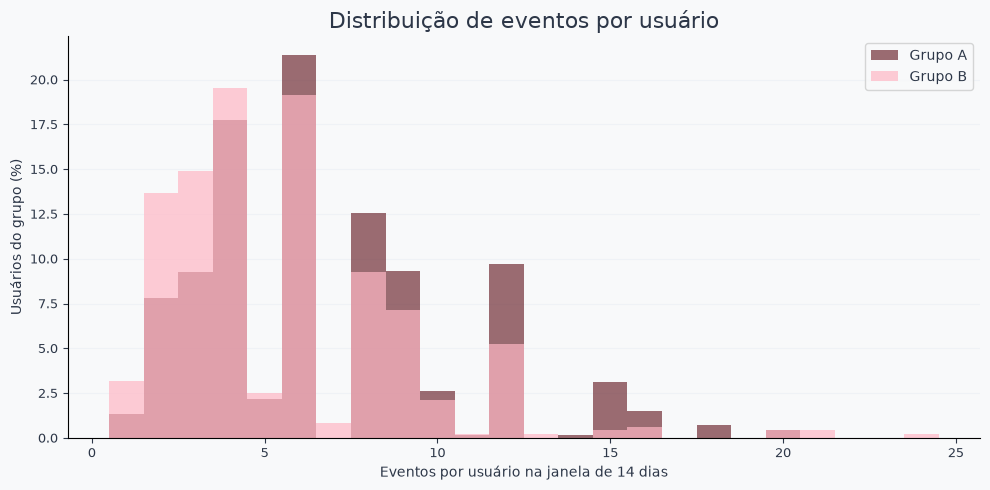

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))

limites = np.arange(
    0.5,
    eventos_por_usuario["quantidade_eventos"].max() + 1.5,
    1
)

for grupo, cor in [("A", CORES["destaque"]), ("B", CORES["comparacao"])]:
    valores = eventos_por_usuario.loc[
        eventos_por_usuario["group"] == grupo,
        "quantidade_eventos"
    ]

    ax.hist(
        valores,
        bins=limites,
        weights=np.ones(len(valores)) * 100 / len(valores),
        color=cor,
        alpha=0.7,
        label=f"Grupo {grupo}"
    )

ax.set_title("Distribuição de eventos por usuário")
ax.set_xlabel("Eventos por usuário na janela de 14 dias")
ax.set_ylabel("Usuários do grupo (%)")
ax.grid(axis="y", alpha=0.4)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

**Resultados — eventos por usuário**

O grupo A apresenta média de 6,79 eventos por usuário e mediana de 6; em B, os valores são 5,53 e 4. O gráfico mostra maior concentração de B nas faixas de poucos eventos.

Há variação dentro dos dois grupos: os valores observados vão de 1 a 20 eventos em A e de 1 a 24 em B. O maior máximo de B não representa maior atividade típica do grupo.

A comparação utiliza percentuais dentro de cada grupo, considerando seus diferentes tamanhos. Os resultados descrevem a atividade registrada na população selecionada; não demonstram, isoladamente, diferença de conversão ou efeito causal da alteração.

As distribuições não são semelhantes em termos de atividade típica: B apresenta média e mediana menores que A. Essa é uma comparação descritiva, sem teste estatístico específico da distribuição.

Embora todos os participantes selecionados tenham uma janela nominal de 14 dias, suas datas de entrada diferem. Assim, os grupos foram observados em combinações distintas de dias do calendário. Isso pode influenciar a atividade registrada, mas não foi demonstrado como causa da diferença.

### 5.2. Distribuição diária dos eventos

Será comparada a quantidade de eventos por dia entre os grupos, considerando a população selecionada e a janela individual de 14 dias.

A interpretação levará em conta os diferentes tamanhos dos grupos, as datas de cadastro e a campanha de Natal e Ano Novo, iniciada em 25/12.

In [17]:
eventos_analise["data_evento"] = (
    eventos_analise["event_dt"].dt.normalize()
)

eventos_por_dia = (
    eventos_analise
    .groupby(["data_evento", "group"])
    .size()
    .unstack(fill_value=0)
)

tabela_eventos_dia = eventos_por_dia.copy()
tabela_eventos_dia.index = (
    tabela_eventos_dia.index.strftime("%d/%m/%Y")
)

display(
    formatar_tabela(
        tabela_eventos_dia,
        formatos=lambda valor: f"{valor:,.0f}".replace(",", ".")
    )
)

group,A,B
data_evento,,
07/12/2020,221,268
08/12/2020,239,169
09/12/2020,282,250
10/12/2020,246,182
11/12/2020,264,115
12/12/2020,273,150
13/12/2020,233,103
14/12/2020,755,193
15/12/2020,780,164


In [18]:
dia_verificado = pd.Timestamp("2020-12-25")

eventos_dia_completo = (
    eventos["event_dt"].dt.normalize() == dia_verificado
)

eventos_dia_analise = (
    eventos_analise["event_dt"].dt.normalize() == dia_verificado
)

verificacao_natal = pd.DataFrame({
    "Eventos em 25/12": [
        eventos_dia_completo.sum(),
        eventos_dia_analise.sum()
    ]
}, index=[
    "Base completa",
    "População e janela de análise"
])

display(formatar_tabela(verificacao_natal, formatos="{:.0f}"))

,Eventos em 25/12
Base completa,0
População e janela de análise,0


**Verificação — ausência de registros em 25/12**

Não há eventos em 25/12/2020 na base completa nem na população selecionada. Portanto, a ausência nessa data não foi causada pelos filtros da análise.

Esse resultado sugere uma possível lacuna de coleta ou de disponibilização dos dados, cuja causa não pode ser confirmada com os arquivos fornecidos. Não será interpretado como ausência comprovada de atividade dos usuários.

As janelas que incluem essa data podem ter eventos não observados, o que limita a interpretação das conversões.

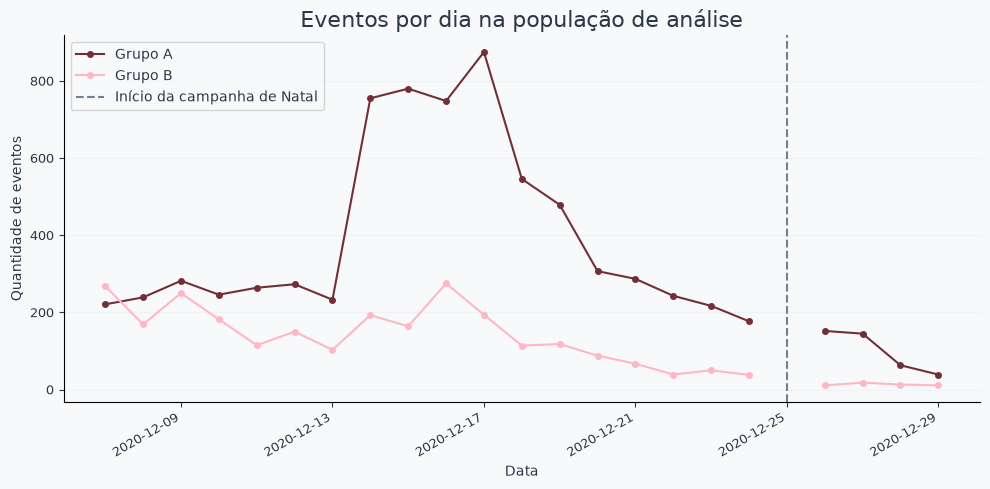

In [19]:
dias_analise = pd.date_range(
    inicio_teste,
    populacao_analise["first_date"].max() + pd.Timedelta(days=13)
)

eventos_diarios_grafico = eventos_por_dia.reindex(dias_analise).copy()

# Remove os zeros inseridos anteriormente nos dias sem registros dos dois grupos.
dias_sem_registros = eventos_diarios_grafico.eq(0).all(axis=1)
eventos_diarios_grafico.loc[dias_sem_registros] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))

for grupo, cor in [("A", CORES["destaque"]), ("B", CORES["comparacao"])]:
    ax.plot(
        eventos_diarios_grafico.index,
        eventos_diarios_grafico[grupo],
        color=cor,
        marker="o",
        markersize=4,
        label=f"Grupo {grupo}"
    )

ax.axvline(
    pd.Timestamp("2020-12-25"),
    color=CORES["apoio"],
    linestyle="--",
    label="Início da campanha de Natal"
)

ax.set_title("Eventos por dia na população de análise")
ax.set_xlabel("Data")
ax.set_ylabel("Quantidade de eventos")
ax.grid(axis="y", alpha=0.4)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Resultados — distribuição diária dos eventos**

A apresenta aumento de 233 eventos em 13/12 para 755 em 14/12, atingindo o máximo de 875 em 17/12. O salto coincide com o aumento de cadastros de A observado no diagnóstico do teste, sendo compatível com a entrada de mais participantes. Essa coincidência não quantifica quanto do aumento decorre dos novos cadastros.

Em B, o maior volume ocorre em 16/12, com 275 eventos. Os volumes absolutos também refletem os diferentes tamanhos e as datas de entrada dos grupos.

Após 17/12, os volumes diminuem. A população selecionada não recebe novos cadastros após essa data, e as janelas individuais terminam progressivamente.

Não há eventos em 25/12 na base completa, indicando uma possível lacuna nos registros. Em 30/12, não há eventos na seleção analisada. Os dias sem registros são apresentados como lacunas no gráfico.

A campanha de Natal começa em 25/12, mas não é possível atribuir a ela as variações observadas. A ausência de registros nessa data também limita a avaliação de seu possível efeito.

### 5.3. Conversões por evento

Para comparar o alcance de cada evento entre os grupos, a conversão será calculada como:

**Usuários únicos que realizaram o evento na janela de 14 dias ÷ total de participantes do grupo × 100.**

Serão avaliados `product_page`, `product_cart` e `purchase`. Os denominadores serão os participantes da população selecionada: 1.115 em A e 476 em B.

Cada usuário será contado uma única vez por evento. Não será exigida sequência temporal nem realização das etapas anteriores; uma compra será contabilizada mesmo sem registro de carrinho.

A meta será interpretada como aumento relativo de pelo menos 10% em B em relação a A. Por exemplo, passar de 20% para 22% representa aumento relativo de 10%, equivalente a 2 pontos percentuais.

As diferenças observadas e o atendimento à meta serão apresentados separadamente da significância estatística, avaliada posteriormente com testes z para proporções.

In [20]:
etapas = ["product_page", "product_cart", "purchase"]

participantes_por_grupo = (
    populacao_analise.groupby("group")["user_id"].nunique()
)

usuarios_por_evento = (
    eventos_analise
    .groupby(["event_name", "group"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=etapas, columns=["A", "B"], fill_value=0)
)

conversoes = usuarios_por_evento.div(
    participantes_por_grupo,
    axis="columns"
) * 100

resumo_conversoes = pd.DataFrame({
    "Usuários A": usuarios_por_evento["A"],
    "Usuários B": usuarios_por_evento["B"],
    "Conversão A (%)": conversoes["A"],
    "Conversão B (%)": conversoes["B"]
})

display(
    formatar_tabela(
        resumo_conversoes,
        formatos={
            "Usuários A": lambda valor: f"{valor:,.0f}".replace(",", "."),
            "Usuários B": lambda valor: f"{valor:,.0f}".replace(",", "."),
            "Conversão A (%)": lambda valor: f"{valor:.2f}".replace(".", ","),
            "Conversão B (%)": lambda valor: f"{valor:.2f}".replace(".", ",")
        }
    )
)

,Usuários A,Usuários B,Conversão A (%),Conversão B (%)
event_name,,,,
product_page,723,265,"64,84","55,67"
product_cart,350,139,"31,39","29,20"
purchase,333,132,"29,87","27,73"


In [21]:
comparacao_conversoes = pd.DataFrame({
    "Conversão A (%)": conversoes["A"],
    "Conversão B (%)": conversoes["B"],
    "Diferença B − A (p.p.)": conversoes["B"] - conversoes["A"],
    "Variação relativa (%)": (
        conversoes["B"] / conversoes["A"] - 1
    ) * 100,
    "Meta para B (%)": conversoes["A"] * 1.10
})

display(
    formatar_tabela(
        comparacao_conversoes,
        formatos=lambda valor: f"{valor:.2f}".replace(".", ",")
    )
)

,Conversão A (%),Conversão B (%),Diferença B − A (p.p.),Variação relativa (%),Meta para B (%)
event_name,,,,,
product_page,"64,84","55,67","-9,17","-14,14","71,33"
product_cart,"31,39","29,20","-2,19","-6,97","34,53"
purchase,"29,87","27,73","-2,13","-7,15","32,85"


**Resultados — conversões por evento**

As conversões observadas em B foram menores que em A nos três eventos:

- `product_page`: 64,84% em A e 55,67% em B; diferença de −9,17 pontos percentuais e variação relativa de −14,14%.
- `product_cart`: 31,39% em A e 29,20% em B; diferença de −2,19 pontos percentuais e variação relativa de −6,97%.
- `purchase`: 29,87% em A e 27,73% em B; diferença de −2,13 pontos percentuais e variação relativa de −7,15%.

A meta de aumento relativo de pelo menos 10% não foi atingida nas estimativas observadas em nenhuma etapa.

Esses resultados são descritivos. Os testes z avaliarão se há evidência estatística de diferenças entre os grupos. As limitações de execução e seleção da amostra permanecem relevantes para a interpretação.

### 5.4. Análise complementar — avanço entre etapas

As conversões anteriores medem o alcance de cada evento em relação ao total de participantes. Esta análise complementar examina o avanço dos mesmos usuários pela sequência `product_page → product_cart → purchase`.

Serão mantidos a população selecionada e os eventos dentro da janela individual de 14 dias. Para compor o funil, cada etapa deverá ocorrer após a anterior, conforme os horários registrados.

Serão apresentadas as quantidades de usuários por etapa e as conversões de página para carrinho e de carrinho para compra, separadamente por grupo.

Compras sem a sequência anterior registrada continuam incluídas nas conversões por evento, mas não integram o funil completo. Eventos com horários iguais não permitem confirmar a ordem e não serão considerados como avanço nessa análise.

A comparação será descritiva, sem novos testes estatísticos. Possíveis lacunas de coleta limitam a interpretação: ausência de uma etapa registrada não comprova abandono.

In [22]:
# Primeira página de produto registrada por usuário
primeira_pagina_funil = (
    eventos_analise.loc[
        eventos_analise["event_name"] == "product_page"
    ]
    .groupby("user_id")["event_dt"]
    .min()
    .rename("pagina_dt")
)

# Primeiro carrinho posterior à página
carrinhos_funil = (
    eventos_analise.loc[
        eventos_analise["event_name"] == "product_cart",
        ["user_id", "event_dt"]
    ]
    .merge(
        primeira_pagina_funil,
        on="user_id",
        how="inner",
        validate="many_to_one"
    )
)

primeiro_carrinho_funil = (
    carrinhos_funil.loc[
        carrinhos_funil["event_dt"] > carrinhos_funil["pagina_dt"]
    ]
    .groupby("user_id")["event_dt"]
    .min()
    .rename("carrinho_dt")
)

# Primeira compra posterior ao carrinho elegível
compras_funil = (
    eventos_analise.loc[
        eventos_analise["event_name"] == "purchase",
        ["user_id", "event_dt"]
    ]
    .merge(
        primeiro_carrinho_funil,
        on="user_id",
        how="inner",
        validate="many_to_one"
    )
)

primeira_compra_funil = (
    compras_funil.loc[
        compras_funil["event_dt"] > compras_funil["carrinho_dt"]
    ]
    .groupby("user_id")["event_dt"]
    .min()
    .rename("compra_dt")
)

# Preservar todos os participantes e identificar seu avanço
funil_usuarios = (
    populacao_analise[["user_id", "group"]]
    .merge(
        primeira_pagina_funil,
        on="user_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        primeiro_carrinho_funil,
        on="user_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        primeira_compra_funil,
        on="user_id",
        how="left",
        validate="one_to_one"
    )
)

resumo_funil = (
    funil_usuarios.groupby("group")
    .agg(
        Participantes=("user_id", "size"),
        Página=("pagina_dt", "count"),
        Carrinho=("carrinho_dt", "count"),
        Compra=("compra_dt", "count")
    )
    .reindex(["A", "B"])
)

resumo_funil["Página → carrinho (%)"] = (
    resumo_funil["Carrinho"]
    .div(resumo_funil["Página"].replace(0, np.nan))
    * 100
)

resumo_funil["Carrinho → compra (%)"] = (
    resumo_funil["Compra"]
    .div(resumo_funil["Carrinho"].replace(0, np.nan))
    * 100
)

display(
    formatar_tabela(
        resumo_funil,
        formatos={
            "Participantes": lambda valor: f"{valor:,.0f}".replace(",", "."),
            "Página": "{:.0f}",
            "Carrinho": "{:.0f}",
            "Compra": "{:.0f}",
            "Página → carrinho (%)": lambda valor: f"{valor:.2f}".replace(".", ","),
            "Carrinho → compra (%)": lambda valor: f"{valor:.2f}".replace(".", ",")
        }
    )
)

,Participantes,Página,Carrinho,Compra,Página → carrinho (%),Carrinho → compra (%)
group,,,,,,
A,1.115,723,207,49,"28,63","23,67"
B,476,265,62,16,"23,40","25,81"


**Resultados — funil sequencial**

No grupo A, 723 usuários acessaram uma página de produto; 207 registraram um carrinho posterior e 49 completaram a sequência com uma compra posterior ao carrinho. No grupo B, essas contagens foram 265, 62 e 16.

A conversão de página para carrinho foi de 28,63% em A e 23,40% em B, uma diferença de −5,23 pontos percentuais para B.

Entre os usuários com página e carrinho em sequência, a conversão para compra foi de 23,67% em A e 25,81% em B. Essa diferença descritiva de +2,14 pontos percentuais não demonstra vantagem estatística ou efeito causal: os denominadores são pequenos e representam usuários selecionados pelo próprio avanço no funil.

A maior perda proporcional observada ocorreu na transição de página para carrinho nos dois grupos. Esse ponto merece investigação, sem interpretar a ausência de avanço registrado como abandono comprovado.

As contagens de compras do funil são inferiores às conversões por evento porque exigem a sequência temporal completa, com horários estritamente posteriores. Compras sem essa sequência observada continuam incluídas na análise anterior.

As possíveis lacunas de coleta e a impossibilidade de ordenar eventos com horários iguais limitam esta análise. Os resultados complementam as conversões gerais e não alteram os testes estatísticos apresentados a seguir.

## 6. Avaliação estatística

Serão aplicados testes z para comparar as proporções de usuários que realizaram `product_page`, `product_cart` e `purchase` entre os grupos A e B.

### 6.1. Hipóteses e critérios

Para cada evento:

- **H0:** as proporções de conversão são iguais em A e B.
- **H1:** as proporções de conversão são diferentes.

A alternativa será bilateral, pois diferenças favoráveis ou desfavoráveis a B são relevantes para avaliar a alteração.

Será adotado nível de significância global de 5%. Como serão realizadas três comparações, será utilizada a correção de Bonferroni: 0,05 ÷ 3, resultando em aproximadamente 0,0167 por teste. Essa é uma escolha metodológica para controlar o risco de falsos positivos no conjunto das comparações.

Antes da aplicação, serão conferidas as quantidades de usuários que realizaram e não realizaram cada evento. Não há participantes compartilhados entre A e B, mas as limitações de execução permanecem relevantes para a interpretação.

O teste avalia diferenças entre proporções, sem testar diretamente a meta de aumento relativo de 10%. Não rejeitar H0 não comprova igualdade entre os grupos.

In [23]:
condicoes_teste = pd.DataFrame({
    "Realizaram A": usuarios_por_evento["A"],
    "Não realizaram A": (
        participantes_por_grupo["A"] - usuarios_por_evento["A"]
    ),
    "Realizaram B": usuarios_por_evento["B"],
    "Não realizaram B": (
        participantes_por_grupo["B"] - usuarios_por_evento["B"]
    )
})

condicoes_teste["Todas as contagens ≥ 10"] = (
    condicoes_teste >= 10
).all(axis=1)

display(
    formatar_tabela(
        condicoes_teste,
        formatos={
            "Realizaram A": "{:.0f}",
            "Não realizaram A": "{:.0f}",
            "Realizaram B": "{:.0f}",
            "Não realizaram B": "{:.0f}"
        }
    )
)

,Realizaram A,Não realizaram A,Realizaram B,Não realizaram B,Todas as contagens ≥ 10
event_name,,,,,
product_page,723,392,265,211,True
product_cart,350,765,139,337,True
purchase,333,782,132,344,True


**Resultado — condições de aplicação**

Nos três eventos, há pelo menos 10 usuários que realizaram e 10 que não realizaram o evento em cada grupo. As contagens atendem ao critério adotado para utilizar a aproximação normal do teste z.

Não há usuários compartilhados entre A e B. Entretanto, essas verificações não comprovam a qualidade da alocação nem eliminam as limitações identificadas na execução do experimento.

### 6.2. Testes z para proporções

Será aplicado um teste bilateral para cada evento, utilizando os totais de participantes e as quantidades de usuários que converteram em A e B.

Serão apresentados a estatística z, o valor-p e a decisão com o limite de significância corrigido por Bonferroni: 0,05 ÷ 3.

A estatística z será calculada como a proporção de B menos a de A, dividida pelo erro-padrão estimado sob H0. Valores negativos indicarão conversão observada menor em B.

In [24]:
alpha = 0.05
alpha_corrigido = alpha / len(etapas)

n_a = participantes_por_grupo["A"]
n_b = participantes_por_grupo["B"]

resultados = []

for evento in etapas:
    conversoes_a = usuarios_por_evento.loc[evento, "A"]
    conversoes_b = usuarios_por_evento.loc[evento, "B"]

    proporcao_a = conversoes_a / n_a
    proporcao_b = conversoes_b / n_b

    proporcao_conjunta = (
        (conversoes_a + conversoes_b) / (n_a + n_b)
    )

    erro_padrao = np.sqrt(
        proporcao_conjunta
        * (1 - proporcao_conjunta)
        * (1 / n_a + 1 / n_b)
    )

    z = (proporcao_b - proporcao_a) / erro_padrao
    valor_p = 2 * stats.norm.sf(abs(z))

    resultados.append({
        "Evento": evento,
        "Estatística z": z,
        "Valor-p": valor_p,
        "Decisão": (
            "Rejeitar H0"
            if valor_p < alpha_corrigido
            else "Não rejeitar H0"
        )
    })

resultados_testes = pd.DataFrame(resultados).set_index("Evento")

print(
    "Limite de significância por teste:",
    f"{alpha_corrigido:.5f}".replace(".", ",")
)

display(
    formatar_tabela(
        resultados_testes,
        formatos={
            "Estatística z": lambda valor: f"{valor:.3f}".replace(".", ","),
            "Valor-p": lambda valor: f"{valor:.6f}".replace(".", ",")
        }
    )
)

Limite de significância por teste: 0,01667


,Estatística z,Valor-p,Decisão
Evento,,,
product_page,"-3,453","0,000555",Rejeitar H0
product_cart,"-0,866","0,386326",Não rejeitar H0
purchase,"-0,857","0,391368",Não rejeitar H0


**Resultados — testes z para proporções**

Com limite de significância de aproximadamente 0,0167 por teste:

- `product_page`: valor-p de 0,000555; rejeita-se H0. Há evidência estatística de diferença, com conversão observada menor em B: 55,67%, contra 64,84% em A.
- `product_cart`: valor-p de 0,386326; não se rejeita H0.
- `purchase`: valor-p de 0,391368; não se rejeita H0.

Para carrinho e compra, os dados não fornecem evidência estatística suficiente de diferença entre os grupos. Isso não comprova igualdade nem ausência de efeito.

A meta de aumento relativo de 10% não foi atingida nas estimativas observadas de nenhum evento. A diferença significativa em `product_page` ocorreu na direção contrária à melhora esperada.

Os resultados se referem à população selecionada. As diferenças na composição temporal, a amostra reduzida e as demais limitações de execução impedem atribuir com segurança as diferenças exclusivamente à alteração testada.

## 7. Conclusões

### Execução do experimento

O teste apresentou divergências em relação ao planejamento: 3.675 participantes, abaixo dos 6.000 esperados; inclusão de 194 usuários de fora da UE; participação de 8,82% dos novos usuários da UE no período, contra os 15% previstos; e 887 participantes vinculados também a outro teste.

Os eventos disponíveis terminam em 30/12/2020, antes do término previsto de 01/01/2021, limitando o acompanhamento dos cadastros mais recentes. Também foram identificadas diferenças na distribuição das datas de entrada entre os grupos e uma campanha de Natal coincidente com parte do experimento.

A análise foi restrita aos participantes da UE, sem vínculo com o outro teste e com cadastro até 17/12, para respeitar o público previsto, evitar sobreposição entre experimentos e uniformizar a janela de observação. Foram considerados somente os eventos do dia do cadastro até o 13º dia seguinte.

A população final contém 1.591 participantes — 1.115 em A e 476 em B — e 10.201 eventos. A amostra reduzida e os diferentes tamanhos dos grupos limitam a precisão das comparações; não invalidam, isoladamente, o teste z.

O corte temporal removeu proporções diferentes dos participantes restantes: 42,50% de A e 27,33% de B. Além disso, não há eventos em 25/12 na base completa, sugerindo uma possível lacuna nos registros. Assim, a janela nominal de 14 dias não garante observação completa, e as diferenças nas datas de cadastro podem gerar exposição distinta dos grupos a essa lacuna e às condições do calendário.

### Resultados do teste A/B

A conversão foi menor em B nos três eventos. A meta de aumento relativo de pelo menos 10% não foi atingida nas estimativas observadas de nenhuma etapa.

Nos testes z bilaterais, com correção de Bonferroni para três comparações, apenas `product_page` apresentou diferença estatisticamente significativa: 64,84% em A e 55,67% em B, com valor-p de 0,000555.

Para `product_cart` e `purchase`, não houve evidência estatística suficiente de diferença. Esses resultados não comprovam igualdade entre os grupos.

A menor atividade típica de B — média de 5,53 eventos por usuário e mediana de 4, contra 6,79 e 6 em A — acompanha as menores conversões observadas nesse grupo. Esse resultado descritivo complementa a análise, mas não demonstra a causa das diferenças. O aumento de cadastros e eventos de A a partir de 14/12 reforça a importância de considerar a composição temporal dos grupos ao interpretar o teste.

Na análise complementar do funil sequencial, o avanço de página para carrinho foi de 28,63% em A e 23,40% em B. Essa transição apresentou a maior perda proporcional observada nos dois grupos e merece investigação. Entre os usuários que chegaram ao carrinho pela sequência exigida, 23,67% em A e 25,81% em B registraram uma compra posterior. Essa comparação é descritiva, utiliza grupos selecionados pelo avanço no funil e não demonstra vantagem causal de B. A exigência de ordem temporal e as possíveis lacunas de coleta também limitam sua interpretação.

### Recomendação e limites

Os dados analisados não sustentam recomendar a implementação da alteração com base no benefício esperado. A menor conversão em `product_page` merece investigação, mas as limitações de execução impedem atribuí-la com segurança exclusivamente à intervenção.

Recomenda-se esclarecer as divergências de recrutamento, alocação e coleta antes de realizar um novo experimento, garantindo público elegível, acompanhamento completo e planejamento amostral adequado.

As conclusões se aplicam à população selecionada e aos registros fornecidos, sem generalização automática para todos os usuários da loja.